# Assignment 1: EDA and baseline

**Group 43, CENG313** · Mehmet Emircan Küllücek (24118080060) · Aleksei Khlopkov (23118080404)

Competition: [PhysioNet – Digitization of ECG Images](https://www.kaggle.com/competitions/physionet-ecg-image-digitization) (Kaggle, Oct 2025 – Jan 2026). It is closed but still accepts late submissions, which we use in section 6.

## 1. Problem definition

**Task.** Hospitals hold many ECGs only on paper. Given one picture of a printed 12-lead ECG (a clean render, a scan or a phone photo, sometimes stained or damaged), recover the 12 voltage curves that were printed on it.

**Target.** For every image and each of the 12 leads, the voltage in mV at every sample of the original recording: `fs × 2.5 s` values for 11 leads and `fs × 10 s` for lead II, where the sampling rate `fs` is given. So the target is not one label per row but a long numeric sequence per image (a regression of thousands of values). The input is the image only.

**Metric.** Signal-to-noise ratio in dB (official code vendored in `src/metric.py`):
1. per lead, the prediction may be shifted in time by up to 0.2 s and by any constant offset, whichever fits best;
2. signal power (truth²) and noise power ((truth − prediction)²) are summed over the 12 leads of an image; their ratio is the image's SNR;
3. the score is 10·log10 of the **mean** SNR over all images. Higher is better, predicting all zeros gives about 0 dB, a perfect image is capped at 60 dB.

**This notebook:** 2. data overview · 3. EDA of the signals, the images and the metric · 4. preprocessing decisions · 5. two baselines on a validation split · 6. Kaggle late submission · 7. conclusion.

All reusable code is in the `src` package (`data.py`, `models.py`, `utils.py`, the official metric and the page template). The notebook only imports it.

**Setup.** Run the cell below first. In Colab it clones this (public) repository; locally, start Jupyter from the repo root. Either way it downloads our data subset (about 2.5 GB) into `data/` on the first run.

In [1]:
# In Colab: clone the repo. Locally: start Jupyter from the repo root.
# Then fetch the data subset into data/ (first run only).
import os, sys

if "google.colab" in sys.modules and not os.path.isdir("src"):
    !git clone -q https://github.com/ceng313-2026/GROUP43_CENG313.git
    %cd GROUP43_CENG313

from src.data import download_dataset
download_dataset()  # ~2.5 GB on the first run, skipped when data/ exists
print("data ready:", len(os.listdir("data/train")), "record folders")

data ready: 99 record folders


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src import layout
from src.data import load_val_ids, load_record_gt, extract_lead_signal
from src.metric import record_linear_snr, competition_score_from_linear
from src.models import evaluate_zeros, evaluate_classical_cv, score
from src.baseline_cv import geometry_from_image
from src.utils import einthoven_residual, resample_to_rows, submission_frame

DATA = "data"
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
IMAGE_TYPES = ["0001", "0003", "0004", "0005", "0006", "0009", "0010", "0011", "0012"]
REC = 1006427285  # example record shown in the plots

train = pd.read_csv(f"{DATA}/train.csv")
fs_of = dict(zip(train.id, train.fs))
val_ids = load_val_ids()
eval_ids = val_ids[:30]  # fixed evaluation subset for all scores in this notebook
gt_ids = [r for r in val_ids if os.path.exists(f"{DATA}/train/{r}/{r}.csv")]
print(f"train.csv: {len(train)} records | validation split: {len(val_ids)} | "
      f"with ground truth in our subset: {len(gt_ids)} | evaluation subset: {len(eval_ids)}")

train.csv: 977 records | validation split: 98 | with ground truth in our subset: 98 | evaluation subset: 30


## 2. Data overview

The competition data are: `train.csv` (one row per record), for each record a ground-truth CSV with the 12 signals and nine PNG images of the same ECG, `test.csv`, and a sample submission. The full set is 85.75 GB, so we work on a subset of about 2.5 GB: the ground truth of our 98 validation records and all nine images of the first 30 of them (split in section 5).

In [3]:
print("train.csv shape:", train.shape)
print(train.dtypes.to_string())
display(train.describe())
print("missing values per column:", train.isna().sum().to_dict())
print("duplicate rows:", int(train.duplicated().sum()), "| duplicate ids:", int(train.id.duplicated().sum()))

train.csv shape: (977, 3)
id         int64
fs         int64
sig_len    int64


,id,fs,sig_len
count,9.770000e+02,977.000000,977.000000
mean,2.143116e+09,590.055271,5900.552712
std,1.296314e+09,315.892515,3158.925149
min,7.663343e+06,250.000000,2500.000000
25%,9.720851e+08,256.000000,2560.000000
50%,2.112147e+09,500.000000,5000.000000
75%,3.316191e+09,1000.000000,10000.000000
max,4.292119e+09,1025.000000,10250.000000


missing values per column: {'id': 0, 'fs': 0, 'sig_len': 0}
duplicate rows: 0 | duplicate ids: 0


`train.csv` has 977 rows and three integer columns, with no missing values and no duplicates. `id` is only a key; `fs` (sampling rate) takes six values between 250 and 1025 Hz, and `sig_len` is the number of samples (checked in section 3.1).

In [4]:
test = pd.read_csv(f"{DATA}/test.csv")
sample = pd.read_parquet(f"{DATA}/sample_submission.parquet")
print("test.csv shape:", test.shape, "| images:", test.id.nunique(), "| missing values:", int(test.isna().sum().sum()))
display(test.head(3))
print("sample_submission shape:", sample.shape, dict(sample.dtypes.astype(str)))
display(sample.head(3))
print("rows in sample_submission == sum of number_of_rows in test.csv:", len(sample) == test.number_of_rows.sum())

test.csv shape: (24, 4) | images: 2 | missing values: 0


,id,lead,fs,number_of_rows
0,1053922973,I,1000,2500
1,1053922973,II,1000,10000
2,1053922973,III,1000,2500


sample_submission shape: (75000, 2) {'id': 'str', 'value': 'int64'}


,id,value
0,1053922973_0_I,0
1,1053922973_1_I,0
2,1053922973_2_I,0


rows in sample_submission == sum of number_of_rows in test.csv: True


The local `test.csv` only describes two example images (12 rows each: one per lead, with `fs` and the required `number_of_rows`). The real test set (about 1000 images) is hidden and only visible to a notebook running on Kaggle (section 6). The submission is in long format: one row per predicted sample, with `id = {image}_{row}_{lead}`, so two images already need 75,000 rows.

In [5]:
gt = load_record_gt(DATA, REC)
print(f"ground truth of record {REC}: shape {gt.shape} (10 s x {fs_of[REC]} Hz rows, one column per lead), "
      f"dtypes {set(gt.dtypes.astype(str))}")
display(gt.describe().T.round(3))
missing = pd.DataFrame([load_record_gt(DATA, r).isna().mean() for r in gt_ids]).mean().mul(100).round(1)
print(f"missing values per lead, % (mean over {len(gt_ids)} records):", missing.to_dict())
n_png = pd.Series({r: sum(f.endswith(".png") for f in os.listdir(f"{DATA}/train/{r}")) for r in eval_ids})
print("images per evaluation record:", n_png.value_counts().to_dict())

ground truth of record 1006427285: shape (10250, 12) (10 s x 1025 Hz rows, one column per lead), dtypes {'float64'}


,count,mean,std,min,25%,50%,75%,max
I,2562.0,-0.001,0.083,-0.119,-0.036,-0.016,0.003,0.600
II,10250.0,-0.003,0.131,-0.222,-0.070,-0.015,0.008,0.841
III,2562.0,-0.001,0.078,-0.182,-0.044,-0.004,0.015,0.534
aVR,2563.0,0.003,0.086,-0.642,-0.004,0.013,0.036,0.149
aVL,2563.0,0.001,0.034,-0.216,-0.014,0.000,0.014,0.274
aVF,2563.0,-0.004,0.089,-0.128,-0.030,-0.007,0.005,0.650
V1,2562.0,-0.002,0.261,-1.463,0.004,0.024,0.105,0.260
V2,2562.0,-0.005,0.363,-1.950,0.010,0.025,0.146,0.345
V3,2562.0,-0.007,0.324,-1.900,0.015,0.035,0.128,0.264
V4,2563.0,0.006,0.130,-1.037,0.000,0.020,0.060,0.345


missing values per lead, % (mean over 98 records): {'I': 75.0, 'II': 0.0, 'III': 75.0, 'aVR': 75.0, 'aVL': 75.0, 'aVF': 75.0, 'V1': 75.0, 'V2': 75.0, 'V3': 75.0, 'V4': 75.0, 'V5': 75.0, 'V6': 75.0}
images per evaluation record: {9: 30}


- All signal columns are floats in mV, mostly within ±2 mV.
- **Missing values:** each short lead is 75% empty, lead II is complete. This is not lost data: a printed page shows each short lead for only 2.5 s (its quarter of the 10 s), so the CSV holds only that part. We do not impute it (section 4.1).
- **Duplicates:** there are no duplicate rows, but each record comes as nine images of the *same* signal. These are near-duplicates for learning, so train and validation must be split by record, not by image (section 5).

## 3. Exploratory data analysis

We look at the target (the signals), the input (the images), how the metric reacts to errors, and the page layout every method depends on. Each plot is followed by what we read from it.

### 3.1 Sampling rates and lengths

`train.csv` gives each record's sampling rate `fs` and length `sig_len`. `test.csv` lists, for every test image and lead, how many rows the prediction must have.

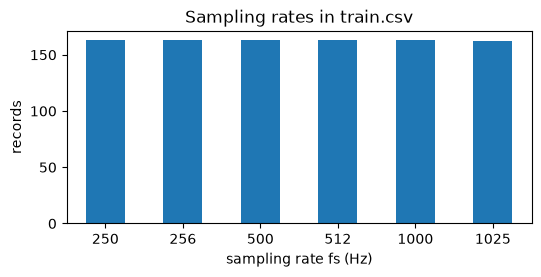

every record is 10 s long (sig_len == 10 * fs): True


,id,lead,fs,number_of_rows
0,1053922973,I,1000,2500
1,1053922973,II,1000,10000
2,1053922973,III,1000,2500
3,1053922973,aVR,1000,2500
4,1053922973,aVL,1000,2500
5,1053922973,aVF,1000,2500
6,1053922973,V1,1000,2500
7,1053922973,V2,1000,2500
8,1053922973,V3,1000,2500
9,1053922973,V4,1000,2500


In [6]:
ax = train.fs.value_counts().sort_index().plot.bar(figsize=(6, 2.5), rot=0, color="tab:blue")
ax.set(xlabel="sampling rate fs (Hz)", ylabel="records", title="Sampling rates in train.csv")
plt.show()
print("every record is 10 s long (sig_len == 10 * fs):", bool((train.sig_len == 10 * train.fs).all()))
pd.read_csv(f"{DATA}/test.csv").head(12)

The six sampling rates are equally common (about 163 records each), and every record is 10 s long. So a prediction has to be resampled to a different number of rows per record; the rate is given, it never has to be guessed. Lead II needs four times as many rows as the other leads (next section explains why).

### 3.2 Ground-truth signals (the target)

The ground-truth CSV has `sig_len` rows for all 12 leads, but most cells are empty. A standard printout shows each lead for only 2.5 s: three rows of four leads, plus lead II again over the full 10 s at the bottom. The CSV mirrors this, so each lead is filled only in its own quarter of the 10 s. Below we draw one record the way it is printed.

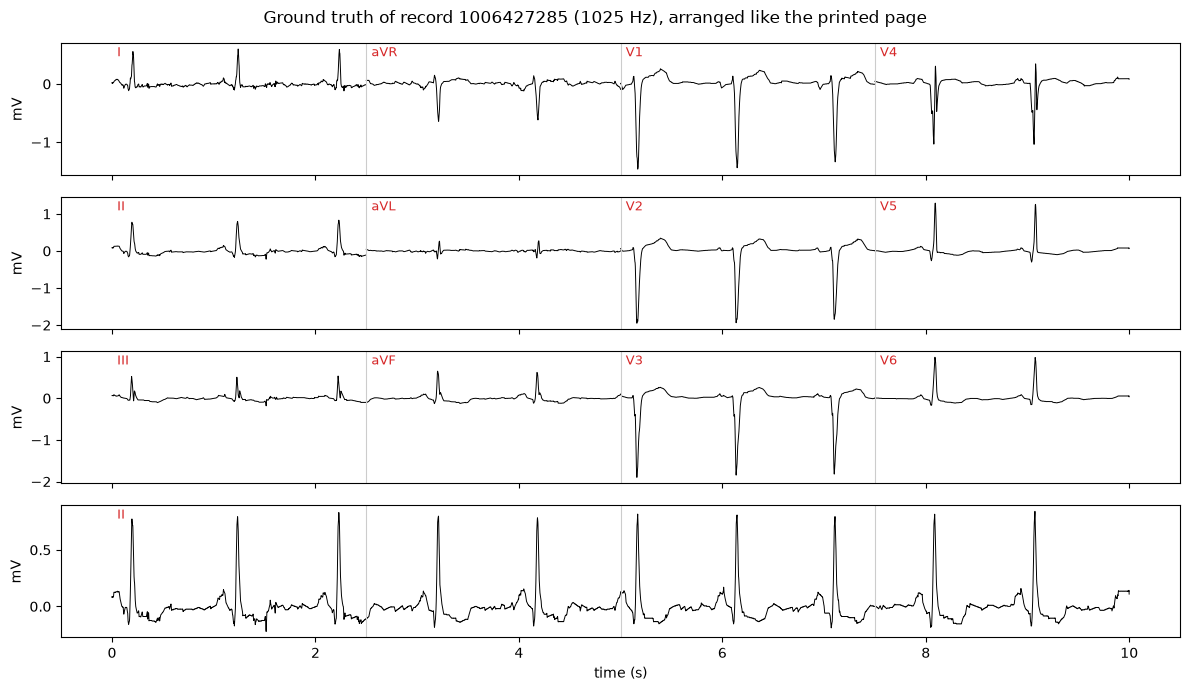

In [7]:
gt = load_record_gt(DATA, REC)
fs = fs_of[REC]
t = np.arange(len(gt)) / fs

fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for i, (ax, row) in enumerate(zip(axes, layout.ROWS + (("II",),))):
    for lead in row:
        s = gt[lead].where(t < 2.5) if (lead == "II" and i < 3) else gt[lead]
        ax.plot(t, s, lw=0.7, color="k")
        start = t[s.notna().values][0]
        ax.text(start + 0.05, 0.9, lead, transform=ax.get_xaxis_transform(), fontsize=9, color="tab:red")
    ax.set_ylabel("mV")
    for q in (2.5, 5, 7.5):
        ax.axvline(q, color="0.8", lw=0.8)
axes[-1].set_xlabel("time (s)")
fig.suptitle(f"Ground truth of record {REC} ({fs} Hz), arranged like the printed page")
plt.tight_layout(); plt.show()

Next, statistics over all records with ground truth in our subset: how many samples each lead has, how big its amplitude is, and how much signal energy it carries.

In [8]:
rows, einthoven = [], []
for r in gt_ids:
    g = load_record_gt(DATA, r)
    einthoven.append(einthoven_residual(g))
    for lead in LEADS:
        s = extract_lead_signal(g, lead)
        rows.append({"record": r, "fs": fs_of[r], "lead": lead, "n": len(s),
                     "peak_to_peak_mV": np.ptp(s), "energy": np.sum((s - s.mean()) ** 2)})
leads = pd.DataFrame(rows)

# Does floor(fs * 2.5) give the right number of rows for a short lead?
leads["floor_rule"] = np.floor(leads.fs * np.where(leads.lead == "II", 10, 2.5)).astype(int)
wrong = leads[leads.n != leads.floor_rule]
print(f"{len(gt_ids)} records, {len(leads)} lead series; floor(fs*2.5) is wrong for {len(wrong)} of them")
wrong.groupby(["fs", "lead"]).agg(true_rows=("n", "first"), floor_rule=("floor_rule", "first")).T

98 records, 1176 lead series; floor(fs*2.5) is wrong for 150 of them


fs          1025                              
lead          V4    V5    V6   aVF   aVL   aVR
true_rows   2563  2563  2563  2563  2563  2563
floor_rule  2562  2562  2562  2562  2562  2562

At 1025 Hz a quarter is 2562.5 samples, so the leads in quarters 2 and 4 get 2563 rows and those in quarters 1 and 3 get 2562. The formula `floor(fs * 2.5)` is wrong for half of the short leads at this rate. Row counts must match exactly for a submission, so we always take lengths from the ground truth or from `number_of_rows` in `test.csv`.

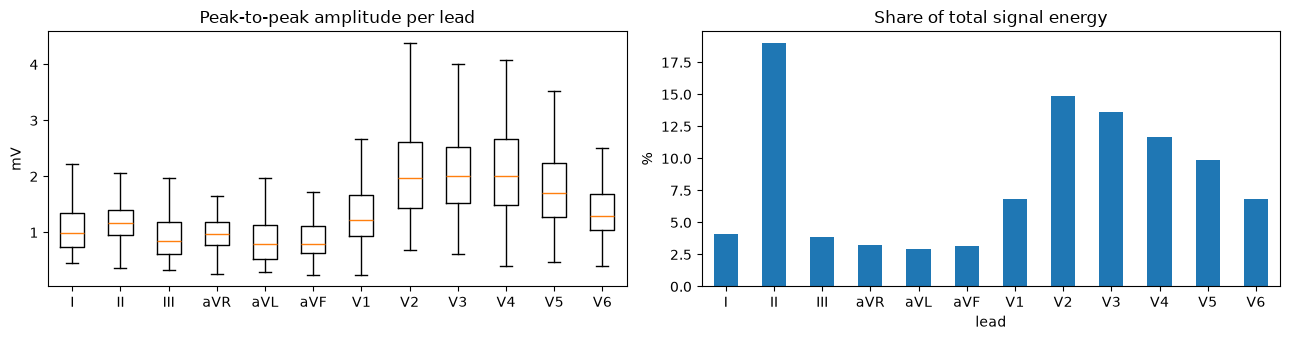

energy share of II + V2 + V3 + V4: 59.2 %


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].boxplot([leads.loc[leads.lead == l, "peak_to_peak_mV"] for l in LEADS], showfliers=False)
ax[0].set_xticks(range(1, 13), LEADS)
ax[0].set(title="Peak-to-peak amplitude per lead", ylabel="mV")
share = leads.groupby("lead").energy.sum().reindex(LEADS) / leads.energy.sum() * 100
share.plot.bar(ax=ax[1], rot=0, color="tab:blue")
ax[1].set(title="Share of total signal energy", ylabel="%")
plt.tight_layout(); plt.show()
print("energy share of II + V2 + V3 + V4:", round(share[["II", "V2", "V3", "V4"]].sum(), 1), "%")

Typical beats are 1–2 mV tall, i.e. 80–160 px on the clean page. The chest leads V2–V4 are the largest, the augmented limb leads aVR/aVL/aVF the smallest.

The energy share matters because the metric adds signal and noise over all 12 leads of an image before dividing (section 3.4). Lead II (long strip) and V2–V4 together hold about 60% of the energy. Getting these four right decides most of the score; an error on aVL costs much less.

In [10]:
e = pd.DataFrame(einthoven)
print("RMS of lead II:                 ", f"{e.rms_II.median() * 1000:7.1f} µV (median)")
print("RMS of II - (I + III):          ", f"{e.rms_resid_III.median() * 1000:7.2f} µV (median)")
print("RMS of aVR + aVL + aVF:         ", f"{e.rms_augmented_sum.median() * 1000:7.2f} µV (median)")

RMS of lead II:                    137.5 µV (median)
RMS of II - (I + III):              0.79 µV (median)
RMS of aVR + aVL + aVF:             1.11 µV (median)


The six limb leads are not independent. By Einthoven's law II = I + III, and the augmented leads sum to zero. In the ground truth both hold to about 1 µV, which is only rounding. So a digitizer gets two free consistency checks, and a badly read limb lead can be repaired from the other two. We plan to use this in Assignment 2.

### 3.3 The nine image types (the input)

Every record comes as nine images of the same ECG. Type `0001` is a clean digital render; the others are the same page printed and then scanned or photographed, some with stains or damage. Below are the nine images of our example record.

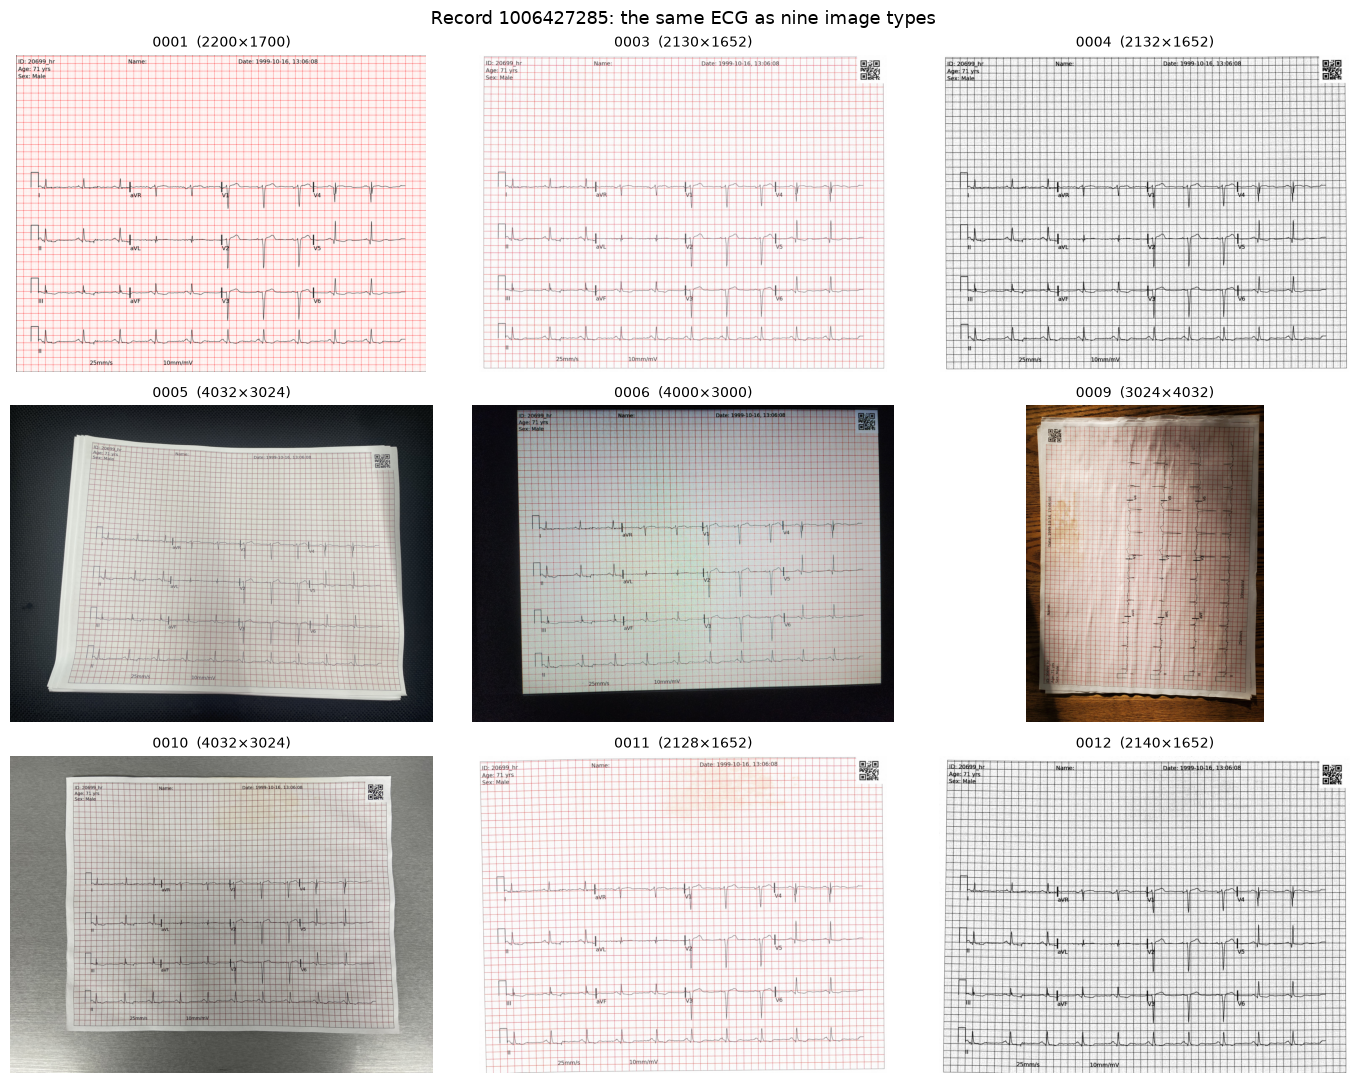

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, typ in zip(axes.ravel(), IMAGE_TYPES):
    im = Image.open(f"{DATA}/train/{REC}/{REC}-{typ}.png")
    w, h = im.size
    im.thumbnail((1000, 1000))
    ax.imshow(im); ax.set_title(f"{typ}  ({w}×{h})", fontsize=10); ax.axis("off")
fig.suptitle(f"Record {REC}: the same ECG as nine image types", fontsize=13)
plt.tight_layout(); plt.show()

In [12]:
img_rows = []
for r in eval_ids:
    for typ in IMAGE_TYPES:
        p = f"{DATA}/train/{r}/{r}-{typ}.png"
        if os.path.exists(p):
            with Image.open(p) as im:  # reads the header only
                img_rows.append({"type": typ, "width": im.width, "height": im.height,
                                 "mode": im.mode, "MB": os.path.getsize(p) / 1e6})
imgs = pd.DataFrame(img_rows)
imgs.groupby("type").agg(images=("width", "size"), width=("width", "median"), height=("height", "median"),
                         portrait=("height", lambda h: (h > imgs.loc[h.index, "width"]).mean()),
                         mode=("mode", lambda m: m.mode()[0]), median_MB=("MB", "median")).round(2)

,images,width,height,portrait,mode,median_MB
type,,,,,,
0001,30,2200.0,1700.0,0.00,RGBA,0.40
0003,30,2129.0,1652.0,0.00,RGB,6.83
0004,30,2132.0,1652.0,0.00,RGB,1.49
0005,30,4032.0,3024.0,0.07,RGB,15.81
0006,30,4000.0,3000.0,0.40,RGB,22.34
0009,30,4032.0,3024.0,0.07,RGB,16.00
0010,30,4032.0,3024.0,0.00,RGB,13.53
0011,30,2134.0,1652.0,0.00,RGB,6.78
0012,30,2140.0,1652.0,0.00,RGB,4.47


What we see (from the example record and the size table):

| type | what it is | why it is hard |
|---|---|---|
| 0001 | clean render, 2200×1700, red grid | nothing; the exact page template |
| 0003, 0011 | colour scans (0011 with stains) | slightly smaller and shifted; faded colours |
| 0004, 0012 | black-and-white scans | the grid is as dark as the trace, so colour can't separate them |
| 0005, 0010 | phone photos of the printout, ~12 MP | perspective, curved paper, background around the page |
| 0006 | photo of the page on a screen | moiré, glare, dark bezel |
| 0009 | phone photo, rotated 90°, stained paper | rotation, stains, uneven light |

Only `0001` matches the page template pixel for pixel. Every other type first has to be mapped back onto it (rotation, perspective, scale). This is why the classical baseline below works on clean pages and fails on most others.

### 3.4 How the metric reacts to errors

The official metric (vendored in `src/metric.py`) scores each image as follows:
1. per lead, shift the prediction in time by the best lag within ±0.2 s and remove the best constant offset;
2. add up signal power (truth²) and noise power ((truth − prediction)²) over all 12 leads;
3. SNR of the image = signal / noise. The final score is 10·log10 of the **mean SNR over images**; a perfect image is capped at 60 dB.

To see what this rewards, we damage the true signals of the 30 evaluation records on purpose and score them.

In [13]:
eval_gt = {r: load_record_gt(DATA, r) for r in eval_ids}

def score_of(transform):
    """Score the ground truth of the evaluation records after applying transform(signal, fs) to every lead."""
    ratios = []
    for r, g in eval_gt.items():
        fs = fs_of[r]
        pred = {lead: transform(extract_lead_signal(g, lead), fs) for lead in LEADS}
        ratios.append(record_linear_snr(g, pred, fs))
    return competition_score_from_linear(ratios)

def delayed(s, k):
    return np.concatenate([np.full(k, s[0]), s[:-k]])

def stretched(s, e):  # read the time axis e (e.g. 1%) too slow
    return np.interp(np.arange(len(s)) * (1 + e), np.arange(len(s)), s)

rng = np.random.default_rng(0)
tests = {
    "all zeros": lambda s, fs: np.zeros_like(s),
    "+0.5 mV offset": lambda s, fs: s + 0.5,
    "delay 0.1 s": lambda s, fs: delayed(s, int(0.1 * fs)),
    "delay 0.3 s": lambda s, fs: delayed(s, int(0.3 * fs)),
    "noise, sd 0.02 mV": lambda s, fs: s + rng.normal(0, 0.02, len(s)),
    "noise, sd 0.05 mV": lambda s, fs: s + rng.normal(0, 0.05, len(s)),
}
for e in (0.02, 0.05, 0.1, 0.2):
    tests[f"amplitude {e:.0%} too large"] = lambda s, fs, e=e: s * (1 + e)
for e in (0.005, 0.01, 0.02):
    tests[f"time axis {e:.1%} stretched"] = lambda s, fs, e=e: stretched(s, e)

metric_tests = pd.Series({name: score_of(f) for name, f in tests.items()}, name="score (dB)").round(2)
metric_tests.to_frame()

,score (dB)
all zeros,0.26
+0.5 mV offset,60.00
delay 0.1 s,21.23
delay 0.3 s,-1.37
"noise, sd 0.02 mV",21.24
"noise, sd 0.05 mV",13.30
amplitude 2% too large,34.24
amplitude 5% too large,26.28
amplitude 10% too large,20.26
amplitude 20% too large,14.24


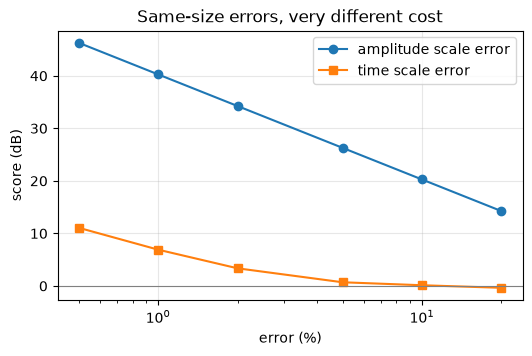

In [14]:
err = np.array([0.5, 1, 2, 5, 10, 20])
gain_db = [score_of(lambda s, fs, e=e: s * (1 + e / 100)) for e in err]
time_db = [score_of(lambda s, fs, e=e: stretched(s, e / 100)) for e in err]
plt.figure(figsize=(6, 3.5))
plt.semilogx(err, gain_db, "o-", label="amplitude scale error")
plt.semilogx(err, time_db, "s-", label="time scale error")
plt.axhline(0, color="0.5", lw=0.8)
plt.xlabel("error (%)"); plt.ylabel("score (dB)"); plt.legend()
plt.title("Same-size errors, very different cost"); plt.grid(alpha=0.3); plt.show()

Lessons for building a digitizer:
- **Vertical offset is free.** We don't need to find the exact 0 mV line, only the right shape and scale.
- **Time shifts up to 0.2 s are found by the metric.** A 0.1 s delay still scores about 21 dB; the loss comes only from the 0.1 s at the start of each lead that is missing. A 0.3 s delay is outside the search window and scores below zero.
- **Amplitude scale errors are moderately expensive.** An error e caps the SNR near 1/e²: 5% → about 26 dB, 10% → about 20 dB.
- **Time-scale errors are the most expensive.** Stretching the time axis by 1% loses more than a 10% amplitude error, because the beats drift out of phase along the strip. Getting px/s right matters more than px/mV.
- **All zeros scores ≈ 0 dB**, not minus infinity. Offset removal lets a flat line explain a little of the signal. So for a hopeless image, predicting zeros beats a wrong guess.

### 3.5 Checking the page template

The baseline and our later work assume a fixed layout of the clean `0001` page (`src/layout.py`): 200 dpi, 25 mm/s and 10 mm/mV, i.e. **196.85 px/s and 78.74 px/mV**, signals starting at x = 118 px, and the 0 mV lines of the four rows at y = 709, 992, 1275 and 1535 px.

We check this directly. We draw the **true** signal at the template position and count how many samples land on dark ink (±2 px). As a control, we draw the ground truth of a *different* record on the same image. If the template is right, the own record should hit almost everywhere and the other record much less.

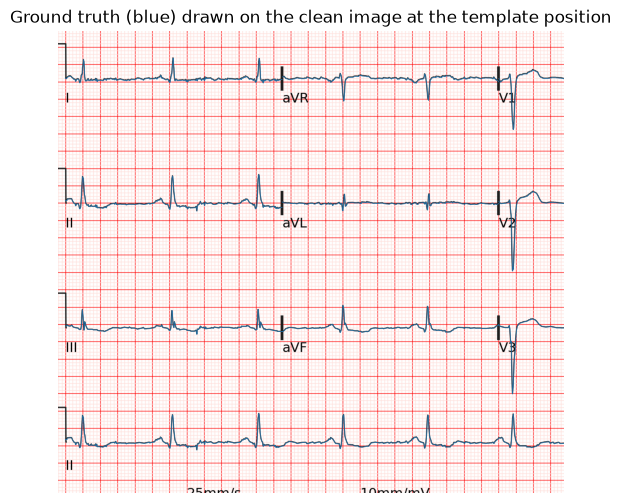

In [15]:
img = np.asarray(Image.open(f"{DATA}/train/{REC}/{REC}-0001.png").convert("RGB"))
gt, fs = load_record_gt(DATA, REC), fs_of[REC]

fig, ax = plt.subplots(figsize=(13, 6))
ax.imshow(img)
for r, row in enumerate(layout.ROWS):
    for c, lead in enumerate(row):
        s = extract_lead_signal(gt, lead)[: int(round(2.5 * fs))]
        ax.plot(*layout.lead_positions(s, fs, r, c), lw=0.6, color="tab:blue", alpha=0.8)
ax.plot(*layout.lead_positions(extract_lead_signal(gt, "II"), fs, 3, 0), lw=0.6, color="tab:blue", alpha=0.8)
ax.set(xlim=(100, 1250), ylim=(1650, 600), title="Ground truth (blue) drawn on the clean image at the template position")
ax.axis("off"); plt.show()

In [16]:
def hit_rates(img_id, gt_id):
    ink = layout.ink_mask(np.asarray(Image.open(f"{DATA}/train/{img_id}/{img_id}-0001.png").convert("RGB")))
    g, fs = load_record_gt(DATA, gt_id), fs_of[gt_id]
    out = {}
    for r, row in enumerate(layout.ROWS):
        for c, lead in enumerate(row):
            s = extract_lead_signal(g, lead)[: int(round(2.5 * fs))]
            out[lead] = layout.ink_hit_rate(ink, *layout.lead_positions(s, fs, r, c))
    out["II (10 s)"] = layout.ink_hit_rate(ink, *layout.lead_positions(extract_lead_signal(g, "II"), fs, 3, 0))
    return out

own = pd.DataFrame([hit_rates(r, r) for r in eval_ids])
other = pd.DataFrame([hit_rates(r, eval_ids[(i + 1) % len(eval_ids)]) for i, r in enumerate(eval_ids)])
pd.DataFrame({"own record, mean": own.mean(), "own record, worst": own.min(),
              "other record, mean": other.mean()}).mul(100).round(1).T

,I,aVR,V1,V4,II,aVL,V2,V5,III,aVF,V3,V6,II (10 s)
"own record, mean",100.0,100.0,100.0,99.9,99.9,100.0,100.0,99.9,100.0,100.0,100.0,99.9,100.0
"own record, worst",99.5,99.8,99.7,99.3,98.8,99.8,99.9,99.2,99.5,99.8,99.8,99.5,99.7
"other record, mean",30.8,32.3,28.8,20.5,26.7,33.8,22.2,25.1,32.2,33.0,21.6,31.2,27.9


On all 30 clean images, practically every true sample of every lead lands on ink at the template position, while the control (another record's signal) hits far less. So the template is right, for every lead including the 10 s strip. On type `0001` the whole problem is reading the trace; the geometry is known.

## 4. Preprocessing

Our data have no categorical features to encode and nothing to scale: the input is an image and the output must stay in physical units (mV), because the metric punishes any wrong amplitude scale (section 3.4). Preprocessing here means four decisions:
1. how to turn the ground-truth CSV into one clean series per lead (no imputation);
2. what to do with extreme amplitudes (keep them);
3. how to turn an image into a trace mask and a pixel-to-mV/second scale;
4. how to resample a trace to the exact number of rows.

Each one is checked with a number below.

### 4.1 Target series: cut, don't impute

`extract_lead_signal` (`src/data.py`) keeps each lead's contiguous non-empty span instead of filling the NaN. We check that the spans have no holes and start where the page layout says.

In [17]:
first, gaps = {lead: [] for lead in LEADS}, 0
for r in gt_ids:
    g = load_record_gt(DATA, r)
    for lead in LEADS:
        filled = np.flatnonzero(np.isfinite(g[lead].values))
        first[lead].append(filled[0] / fs_of[r])
        gaps += int(len(filled) != len(extract_lead_signal(g, lead)))
print(f"{len(gt_ids)} records: leads with a gap inside their span: {gaps}")
pd.DataFrame(first).agg(["min", "max"]).rename(index={"min": "earliest start (s)", "max": "latest start (s)"}).round(2)

98 records: leads with a gap inside their span: 0


,I,II,III,aVR,aVL,aVF,V1,V2,V3,V4,V5,V6
earliest start (s),0.0,0.0,0.0,2.5,2.5,2.5,5.0,5.0,5.0,7.5,7.5,7.5
latest start (s),0.0,0.0,0.0,2.5,2.5,2.5,5.0,5.0,5.0,7.5,7.5,7.5


No lead has a hole, and every lead starts at its quarter of the page in every record (I/II/III at 0 s, aVR/aVL/aVF at 2.5 s, V1–V3 at 5 s, V4–V6 at 7.5 s). Cutting the span is therefore lossless and gives exactly the series the metric compares against. Imputing the empty 7.5 s (with zeros or interpolation) would invent signal that is never scored and would break the row counts.

### 4.2 Outliers: kept

The amplitude boxplot in section 3.2 hid the outliers. We count them with the usual IQR rule and look at the most extreme record.

IQR fence 3.18 mV: 48 of 1176 lead series above it (4.1%), from 23 of 98 records


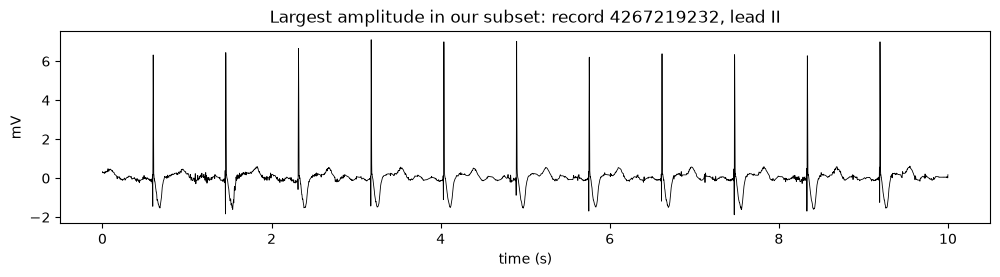

In [18]:
q1, q3 = leads.peak_to_peak_mV.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
high = leads[leads.peak_to_peak_mV > fence]
print(f"IQR fence {fence:.2f} mV: {len(high)} of {len(leads)} lead series above it "
      f"({len(high) / len(leads):.1%}), from {high.record.nunique()} of {len(gt_ids)} records")
r_max = leads.loc[leads.peak_to_peak_mV.idxmax(), "record"]
g = load_record_gt(DATA, r_max)
plt.figure(figsize=(12, 2.5))
plt.plot(np.arange(len(g)) / fs_of[r_max], g["II"], lw=0.6, color="k")
plt.title(f"Largest amplitude in our subset: record {r_max}, lead II"); plt.xlabel("time (s)"); plt.ylabel("mV")
plt.show()

A few percent of the lead series are above the fence. The most extreme one is not a glitch: every beat has the same very tall, narrow QRS spike, so it is a real (abnormal) ECG, and the hidden test will contain such cases too. We keep all of them.

They matter for reading the page, though: at 78.74 px/mV a 6–7 mV spike is about 500 px tall, while the rows are only about 280 px apart. Such spikes cross into the neighbouring row, where a trace follower can jump to the wrong curve.

### 4.3 Image: trace mask and scale

The images come as RGBA (`0001`) or RGB (others) and are converted to RGB first. `src/layout.py` and `src/baseline_cv.py` then
- keep **ink** = pixels that are dark and *not* reddish, which removes the red grid;
- on black-and-white scans, where the grid is dark too, additionally remove lines that run across most of the page;
- measure the **scale** from the grid: one small square is 1 mm = 0.04 s and 0.1 mV, so its pitch in pixels (found by autocorrelation) gives px/s and px/mV.

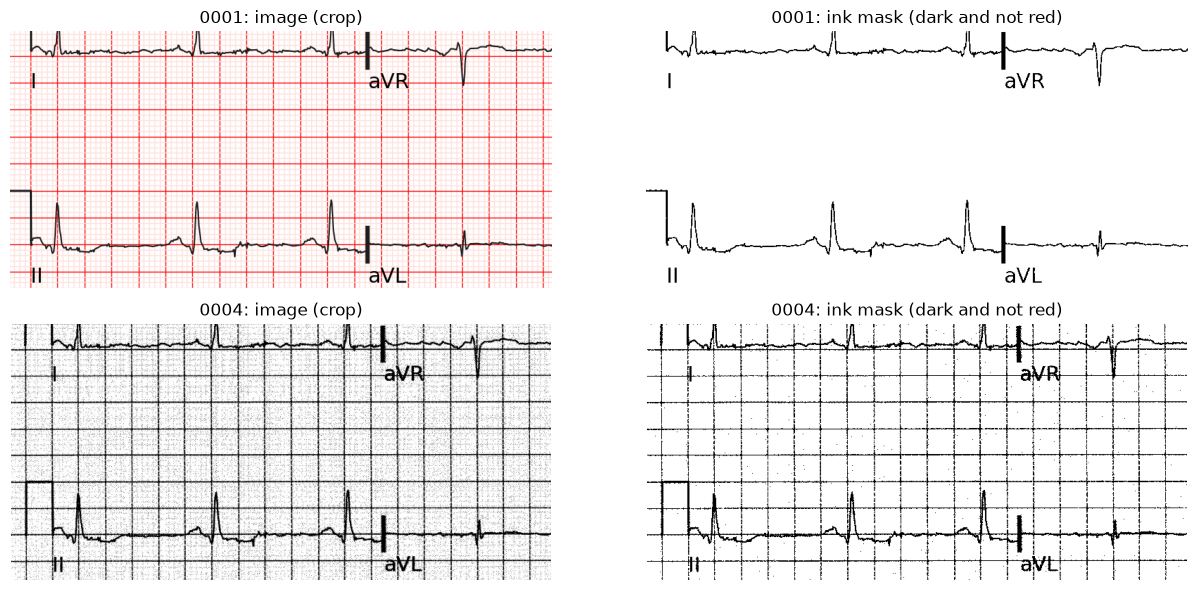

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6))
for row, typ in enumerate(["0001", "0004"]):
    img = np.asarray(Image.open(f"{DATA}/train/{REC}/{REC}-{typ}.png").convert("RGB"))
    H, W = img.shape[:2]
    crop = (slice(int(0.40 * H), int(0.62 * H)), slice(int(0.04 * W), int(0.40 * W)))
    axes[row, 0].imshow(img[crop]); axes[row, 0].set_title(f"{typ}: image (crop)")
    axes[row, 1].imshow(layout.ink_mask(img)[crop], cmap="gray_r"); axes[row, 1].set_title(f"{typ}: ink mask (dark and not red)")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

On the clean page the mask keeps only the trace, the calibration pulse and the lead labels: colour alone separates them from the grid. On the black-and-white scan the grid is grey and survives the colour test, so the mask is covered with grid dots and line pieces. This is why colour-based preprocessing cannot work for types `0004`/`0012`.

Next, how accurate is the scale measured from the grid? On clean pages we know the true values from section 3.5.

In [20]:
calib = []
for r in eval_ids:
    geo = geometry_from_image(np.asarray(Image.open(f"{DATA}/train/{r}/{r}-0001.png").convert("RGB")))
    if geo is not None:
        calib.append({"px per s": geo["px_per_s"], "px per mV": geo["px_per_mV"]})
calib = pd.DataFrame(calib)
err = (calib.mean() / [layout.PX_PER_S, layout.PX_PER_MV] - 1) * 100
print(f"measured from the grid on {len(calib)} clean pages:", calib.mean().round(2).to_dict())
print("true template values:", {"px per s": layout.PX_PER_S, "px per mV": layout.PX_PER_MV})
print("error, %:", err.round(2).to_dict())
print(f"score of the TRUE signal with only this time-scale error: {score_of(lambda s, fs: stretched(s, err['px per s'] / 100)):.1f} dB")

measured from the grid on 30 clean pages: {'px per s': 196.13, 'px per mV': 78.46}
true template values: {'px per s': 196.85, 'px per mV': 78.74}
error, %: {'px per s': -0.37, 'px per mV': -0.35}
score of the TRUE signal with only this time-scale error: 13.1 dB


The grid estimate is off by about 0.4% in both directions, the same on every page (a systematic error of the autocorrelation peak on a grid of only ~7.9 px). That sounds small, but section 3.4 showed that time-scale errors are the most expensive: with this error alone, even a perfectly read trace scores only about 13 dB. This explains a large part of why the classical baseline stays near 8 dB even on clean pages. For type `0001` the fixed template values are the better choice; for scans and photos they only apply after the page has been mapped back onto the template.

### 4.4 Resampling to the required number of rows

A digitizer reads one value per pixel column (about 197 per second), but the target needs `fs` values per second (250–1025) and exactly the required row count (taken from `test.csv` or the ground truth, never from `floor(fs*2.5)`; see 3.2). We use linear interpolation (`resample_to_rows` in `src/utils.py`). To see what it costs, we sample the true signals at pixel resolution, resample them back and score them.

In [21]:
def via_pixel_columns(s, fs):
    n_cols = int(round(len(s) / fs * layout.PX_PER_S))
    cols = np.interp(np.linspace(0, len(s) - 1, n_cols), np.arange(len(s)), s)
    return resample_to_rows(cols, len(s))

def via_pixel_rows(s, fs):
    return np.round(s * layout.PX_PER_MV) / layout.PX_PER_MV

pd.Series({
    "one value per pixel column, linear resampling": score_of(via_pixel_columns),
    "values rounded to whole pixel rows": score_of(via_pixel_rows),
    "both": score_of(lambda s, fs: via_pixel_columns(via_pixel_rows(s, fs), fs)),
}, name="score of the true signal (dB)").round(1).to_frame()

,score of the true signal (dB)
"one value per pixel column, linear resampling",30.0
values rounded to whole pixel rows,36.0
both,29.3


Even a perfect reading of the page cannot beat about 30 dB: QRS spikes last only a few milliseconds, less than one pixel column (5 ms), so their peaks are cut. Rounding to whole pixel rows costs less. This ceiling is far above our baseline (8 dB on clean pages) and above the competition winners (about 23 dB), so linear resampling is good enough for now; sub-pixel reading only matters near the top.

## 5. Baseline models

**Validation split.** The 977 records are split 90/10 **by record** with a fixed seed (`make_split` in `src/data.py`, seed 0). All nine images of a record show the same signal, so splitting by image would put the same ECG on both sides. Neither baseline has parameters to fit, so the training part is not used yet; it is kept for Assignment 2. All local scores use the official metric on the first 30 validation records (30 × 9 = 270 images). The hidden Kaggle test set is our real test (section 6).

### 5.1 Baseline 1: all zeros

Predict 0 mV for every sample. It needs no image at all and sets the floor: any method that scores below it on an image would do better by giving up on that image.

In [22]:
zeros = evaluate_zeros(eval_ids)  # src/models.py
zeros_ratio = dict(zip(zeros.record, zeros.ratio))
zeros_score = score(zeros.ratio)
print(f"all zeros on {len(zeros)} records: {zeros_score:.3f} dB "
      f"(per record {zeros.db.min():.2f} to {zeros.db.max():.2f} dB)")

all zeros on 30 records: 0.262 dB (per record 0.00 to 1.51 dB)


The score is slightly above 0 dB, not exactly 0: the metric removes the best constant offset, so a flat line still "explains" each lead's mean value. Every record scores at least 0 dB this way, which is why zeros is a safe answer for an image we cannot read.

### 5.2 Baseline 2: classical computer vision

`src/baseline_cv.py` (called through `src/models.py`) digitizes an image without any learning:
1. find the grid pitch by autocorrelation and turn it into px/s and px/mV;
2. find the four signal rows from a histogram of dark pixels and cut the page into the template's lead cells;
3. in each cell, follow the dark trace column by column (the run closest to the previous column);
4. convert pixels to mV and resample to the required length. If a cell fails, that lead is predicted as zeros.

We run it on all nine image types of the 30 evaluation records (270 images; this cell is the slow one).

In [23]:
cv = evaluate_classical_cv(eval_ids)  # src/models.py; one row per image
cv["zeros_ratio"] = cv.record.map(zeros_ratio)
cv_score = score(cv.ratio)
print(f"classical CV on {len(cv)} images: {cv_score:.3f} dB")

classical CV on 270 images: 1.023 dB


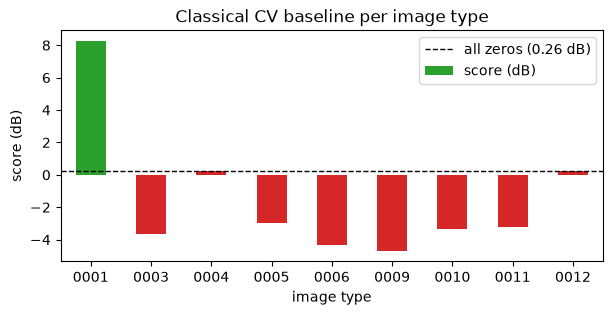

,score (dB),best image (dB),worse than zeros (%),some lead failed (%)
0001,8.26,15.35,3.33,3.33
0003,-3.65,0.29,96.67,6.67
0004,0.21,1.51,6.67,100.00
0005,-2.95,0.84,96.67,66.67
0006,-4.36,0.50,100.00,73.33
0009,-4.70,0.43,90.00,96.67
0010,-3.35,1.32,93.33,96.67
0011,-3.23,0.70,93.33,20.00
0012,0.26,1.51,0.00,100.00


In [24]:
by_type = pd.DataFrame({
    typ: {"score (dB)": score(d.ratio),
          "best image (dB)": d.db.max(),
          "worse than zeros (%)": 100 * (d.ratio < d.zeros_ratio).mean(),
          "some lead failed (%)": 100 * d.status.str.contains("failed|fallback").mean()}
    for typ, d in cv.groupby("variant")
}).T.round(2)

ax = by_type["score (dB)"].plot.bar(figsize=(7, 3), rot=0, color=["tab:green"] + ["tab:red"] * 8)
ax.axhline(zeros_score, color="k", ls="--", lw=1, label=f"all zeros ({zeros_score:.2f} dB)")
ax.set(xlabel="image type", ylabel="score (dB)", title="Classical CV baseline per image type"); ax.legend()
plt.show()
by_type

- **Clean pages work.** On `0001` the baseline scores about 8 dB and its best image about 15 dB, and it is better than zeros on almost every record.
- **Every other type fails.** On colour scans and photos (`0003`, `0005`, `0006`, `0009`, `0010`, `0011`) it is worse than zeros on almost every image: the grid is found, but the page is shifted, rotated or warped, so the fixed cells cut the wrong part of the page or the scale is off. Section 3.4 showed how much a wrong time scale costs.
- **Black-and-white scans fall back to zeros.** On `0004` and `0012` the grid is as dark as the trace, cells fail on every image, and the score equals the zeros floor.

## 6. Kaggle submission

This is a code competition: the test images (about 1000) are hidden and only exist inside a notebook running on Kaggle, which must write `submission.parquet` in the format of section 2. The competition is closed, but Kaggle still scores **late submissions** on the public and private test parts (they are not placed on the leaderboard). We submitted both baselines this way.

`submission_frame` (`src/utils.py`) builds that table from `test.csv` and a dictionary of predictions; any missing or invalid lead becomes zeros, so the file is always accepted. Here it is for the two example test images, with the all-zeros baseline:

In [25]:
sub = submission_frame(test)  # all zeros; pass {(image id, lead): array in mV} for real predictions
print("submission shape:", sub.shape, "| same ids in the same order as sample_submission:", list(sub.id) == list(sample.id))
sub.head(3)

submission shape: (75000, 2) | same ids in the same order as sample_submission: True


,id,value
0,1053922973_0_I,0.0
1,1053922973_1_I,0.0
2,1053922973_2_I,0.0


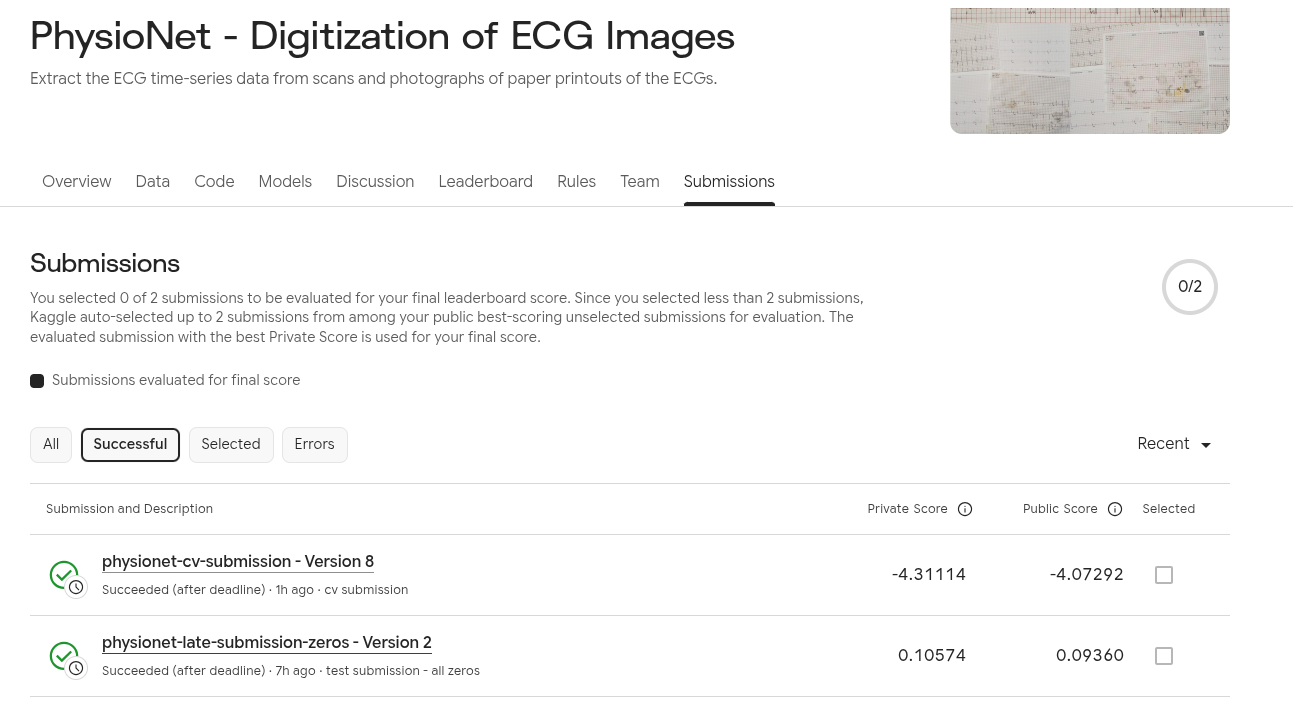

In [26]:
from IPython.display import Image as ShowImage
ShowImage("submissions/submissions.png", width=900)  # Kaggle "Submissions" page

In [27]:
kaggle = pd.DataFrame([
    ("all zeros", 0.10574, 0.09360, zeros_score),
    ("classical CV", -4.31114, -4.07292, cv_score),
], columns=["method", "Kaggle private (dB)", "Kaggle public (dB)", "local validation (dB)"]).set_index("method")
display(kaggle.round(3))

clean = cv.variant == "0001"
print(f"local classical CV without the clean 0001 images: {score(cv[~clean].ratio):.2f} dB; "
      f"the clean images hold {cv[clean].ratio.sum() / cv.ratio.sum():.0%} of the local linear SNR")

,Kaggle private (dB),Kaggle public (dB),local validation (dB)
method,,,
all zeros,0.106,0.094,0.262
classical CV,-4.311,-4.073,1.023


local classical CV without the clean 0001 images: -2.32 dB; the clean images hold 59% of the local linear SNR


- **All zeros** behaves as expected on the hidden test too: about 0.1 dB, close to our local 0.26 dB.
- **Classical CV** scores −4.3 dB on Kaggle (private and public agree), while locally it reached +1.0 dB. The local number is carried by the few clean `0001` pages: they hold most of the local SNR, and without them the local score is clearly negative as well. Because the score averages linear SNR before the log, a handful of good images lifts the whole average. We cannot see the test images, but the result fits a test set with fewer clean renders or more damaged pages than our validation mix. **So the overall local average is misleading on its own; we report scores per image type from now on.**
- For scale: the winning teams reached about 23 dB on the private test. Our baselines are about 27 dB below them.

## 7. Conclusion

### 7.1 Results

In [28]:
results = pd.DataFrame([
    ("all zeros", zeros_score, kaggle.loc["all zeros", "Kaggle private (dB)"], "baseline 1, ours"),
    ("classical CV, all 9 types", cv_score, kaggle.loc["classical CV", "Kaggle private (dB)"], "baseline 2, ours"),
    ("classical CV, clean 0001 only", score(cv[cv.variant == "0001"].ratio), np.nan, "baseline 2, ours"),
    ("public pretrained pipeline (hengck23)", 17.989, np.nan, "reference only, not ours"),
], columns=["method", "local validation (dB)", "Kaggle private (dB)", "note"]).round(3)
results

,method,local validation (dB),Kaggle private (dB),note
0,all zeros,0.262,0.106,"baseline 1, ours"
1,"classical CV, all 9 types",1.023,-4.311,"baseline 2, ours"
2,"classical CV, clean 0001 only",8.260,NaN,"baseline 2, ours"
3,public pretrained pipeline (hengck23),17.989,NaN,"reference only, not ours"


Local scores use the official metric on the same 30 validation records (270 images); Kaggle scores are late submissions on the hidden test set.

The reference row is a public pretrained pipeline shared on Kaggle by hengck23 ([demo notebook](https://www.kaggle.com/code/hengck23/demo-submission)): a learned page rectifier plus U-Net models. Our team ran it on the same 30 records only to see what modern learned methods reach. It is not our work, none of its code is in this repository, and it is not run here.

### 7.2 Key findings

1. **The target is well structured.** Each lead is a 2.5 s span (10 s for lead II) at a known position; the empty cells are layout, not missing data (sections 2, 4.1). Lead II and V2–V4 carry about 60% of the signal energy, so they decide most of the score (3.2).
2. **The metric forgives offsets and small delays but not scale.** A 1% time-scale error costs more than a 10% amplitude error (3.4).
3. **The clean page is fully understood.** The template puts 99.9% of true samples on ink (3.5). Measuring the scale from the grid instead is 0.37% off, which alone caps a perfect trace at 13 dB (4.3).
4. **The classical baseline only works on clean renders** (about 8 dB on `0001`); it is worse than zeros on almost every scan and photo and falls back to zeros on black-and-white scans (5.2).
5. **The local average flatters the baseline.** On the hidden test it scores −4.3 dB, below all zeros (section 6).

### 7.3 Next steps (Assignment 2)

1. **Decide per image when to give up:** predict zeros when a digitization looks wrong (zeros never score below 0 dB). On our data the baseline is worse than zeros on more than half of the images.
2. **Fix the scale:** use the exact template on clean pages, and map scans and photos back onto the template (rotation, perspective) before reading them.
3. **Repair limb leads with Einthoven's law** (II = I + III holds to about 1 µV in the ground truth, section 3.2).
4. Report every result **per image type** and check the main ones with a Kaggle late submission.